In [1]:
import numpy as np
import MAS_library as MASL
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D #only needed for matplotlib 3D projections
import readgadget
import readfof
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import skew
import smoothing_library as SL
import pandas as pd
import void_library as VL

In [9]:
var_ran_lag_dict = np.load("var_random_lagrangian.npz")
var_halos_voids_dict = np.load("var_halos_voids_eulerian.npz")
var_ran_eul_dict = np.load("var_random_eulerian.npz")
print(var_ran_lag_dict)

var_rl = var_ran_lag_dict["var"]
var_h = var_halos_voids_dict["var_h"]
var_v = var_halos_voids_dict["var_v"]
var_fin = var_ran_eul_dict["var"]

n_rl = var_ran_lag_dict["n"]
n_h = var_halos_voids_dict["n_h"]
n_v = var_halos_voids_dict["n_v"]
n_fin = var_ran_eul_dict["n"]

radii= var_halos_voids_dict["radii"]
print(len(radii))


NpzFile 'var_random_lagrangian.npz' with keys: radii, var, n
30


In [7]:
# histograms
def compare(R_target_kpc, nmin=0, bins=40):
    k = np.argmin(np.abs(radii - R_target_kpc))
    def sel(var, n):
        good = (n[:, k] >= nmin) & np.isfinite(var[:, k]) & (var[:, k] > 0)
        #return var[good, k] / var_g, good.mean()
        return var[good,k], good.mean()

    pops = {"random (z=127)":   (var_rl, n_rl, "k"),
            "halos (z=0.5)":    (var_h,  n_h,  "C0"),
            "voids (z=0.5)":    (var_v,  n_v,  "C3"),
            "random (z=0.5)":   (var_fin, n_fin, "C4")}
   

    data = {}
    for name, (var, n, col) in pops.items():
        data[name], frac = sel(var, n)
        print(f"{name:22s} kept {len(data[name]):6d}")

    #for name in ["halos (z=0.5)", "voids (z=0.5)"]:
        #for base in [b for b in data if b.startswith("random")]:
            #print(f"KS {name} vs {base}: p = {ks_2samp(data[base], data[name]).pvalue:.2e}")

    lo = min(a.min() for a in data.values()); hi = max(a.max() for a in data.values())
    edges = np.linspace(lo, hi, bins)
    plt.figure()
    #plt.xlim(0.0,0.001)
    for name, (var, n, col) in pops.items():
        plt.hist(data[name], bins=edges, density=False, histtype="step", color=col,
                 label=f"{name} (N={len(data[name])})")
    plt.xlabel("variance"); plt.ylabel("Count") #density, not count. specifically made to be comparable oops
    plt.title(f"R = {radii[k]/1e3:.1f} Mpc/h"); plt.legend(); plt.show()

compare(3e4)

random (z=127)         kept  10000
halos (z=0.5)          kept  10000
voids (z=0.5)          kept  10000


IndexError: index 21 is out of bounds for axis 1 with size 15

512


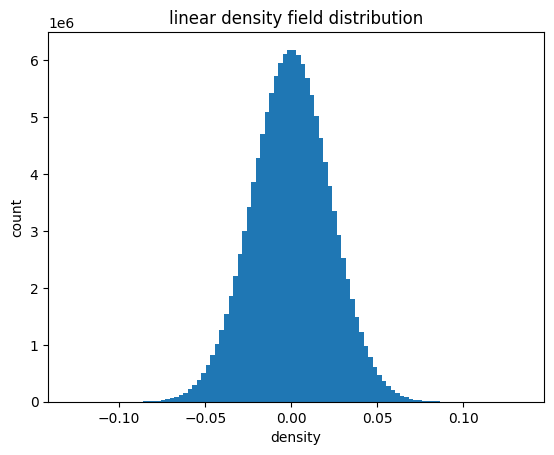

In [2]:
#extracting: linear density; plotting histogram of linear density field
delta_L = np.load("delta_np.npy")
lin_ic = np.load("linICfield.npy")

#print("delta:",delta_L[:, 0])
#print("linIC:",lin_ic[:, 0])

delta_L_flat = delta_L.flatten()
plt.hist(delta_L_flat, bins=100)

plt.title("linear density field distribution")
plt.xlabel("density")
plt.ylabel("count")

print(len(delta_L))

In [3]:
# extracting: positions, IDs

snap_init = "./ICs_Quijote/ics"
snap_final = "./snaps/snap_003"

ptype = [1]

box_size = readgadget.header(snap_init).boxsize #kpc/h
all_init_IDs = readgadget.read_block(snap_init, "ID  ", ptype).astype(np.int64)
all_final_IDs = readgadget.read_block(snap_final,"ID  ", ptype).astype(np.int64)
all_init_positions = readgadget.read_block(snap_init, "POS ", ptype)
all_final_positions = readgadget.read_block(snap_final, "POS ", ptype)

sort_order = np.argsort(all_final_IDs)
final_positions_sorted = all_final_positions[sort_order] #this is the final positions sorted by particle ID, this should be enough for a one-one correspondence to interpolated linear density onto initial positions later on
#tl;dr it's in the same order as all_init_IDs now

In [4]:
#SMOOTHING 
grid = 512
R = 3.5e3 #smoothing scale in kpc/h #unsure as to how to choose this
Filter = 'Gaussian'
threads = 4

#this computes the FFT of the filter (?)
W_k = SL.FT_filter(box_size, R, grid, Filter, threads)

delta_L_smoothed = SL.field_smoothing(delta_L, W_k, threads)

In [4]:
#interpolation back to particles using NGP (claude)

def ngp_readout(field, pos, L, chunk=1 << 24):
    """field: (N,N,N) array indexed [x,y,z]; pos: (Np,3) in the same units as L."""
    N = field.shape[0]
    ff = field.ravel()                      # view if C-contiguous, so make sure it is
    s = N / L
    out = np.empty(len(pos), dtype=field.dtype)
    for a in range(0, len(pos), chunk):     # chunking keeps temporaries small for ~512³ particles
        p = pos[a:a + chunk]
        ix = (p[:, 0] * s+0.5).astype(np.int64)
        iy = (p[:, 1] * s+0.5).astype(np.int64)
        iz = (p[:, 2] * s+0.5).astype(np.int64) #NOTE: THE + 0.5 IS ASSUMING THE VALUES SIT AT THE NODES, VERIFY WHY
        ix %= N; iy %= N; iz %= N           # periodic wrap, also catches x == L
        flat = ix * (N * N)                 # max ~1.3e8, fits in int32
        flat += iy * N
        flat += iz
        out[a:a + chunk] = ff.take(flat)
    return out

delta_L_p = ngp_readout(delta_L, all_init_positions, box_size) 
#delta_L_sm_p = ngp_readout(delta_L_smoothed, all_init_positions, box_size)

#this is enough for lagrangian tracking
#print(delta_L_sm_p.shape)

In [ ]:
#asserting the correct sorting of init ids, they were not in order before
N = 512
init_order = np.argsort(all_init_IDs)

all_init_IDs       = all_init_IDs[init_order]
all_init_positions = all_init_positions[init_order]
delta_L_p          = delta_L_p[init_order]
#delta_L_sm_p       = delta_L_sm_p[init_order]

assert np.array_equal(all_init_IDs, np.arange(1, N**3 + 1)), "IDs are not a permutation of 1..N"srF

In [7]:
#In sphere
def in_sphere(pos, delta_p, centre, R, L):
    d = pos - np.asarray(centre, dtype=pos.dtype)   # displacement from centre
    d -= L * np.round(d / L)                         # periodic: use nearest image
    mask = (d**2).sum(axis=1) < R**2                 # inside sphere?
    return delta_p[mask]

#init_density_insphere = in_sphere(all_init_positions,delta_L_sm_p,(0.8e6,0.8e6,0.8e6),3.7e5,box_size)
#init_density_var = np.var(init_density_insphere)

#print(init_density_var)

#final_density_insphere = in_sphere(final_positions_sorted,delta_L_sm_p,(0.8e6,0.8e6,0.8e6),3.7e5,box_size)
#final_density_var = np.var(final_density_insphere)

#print(final_density_var)

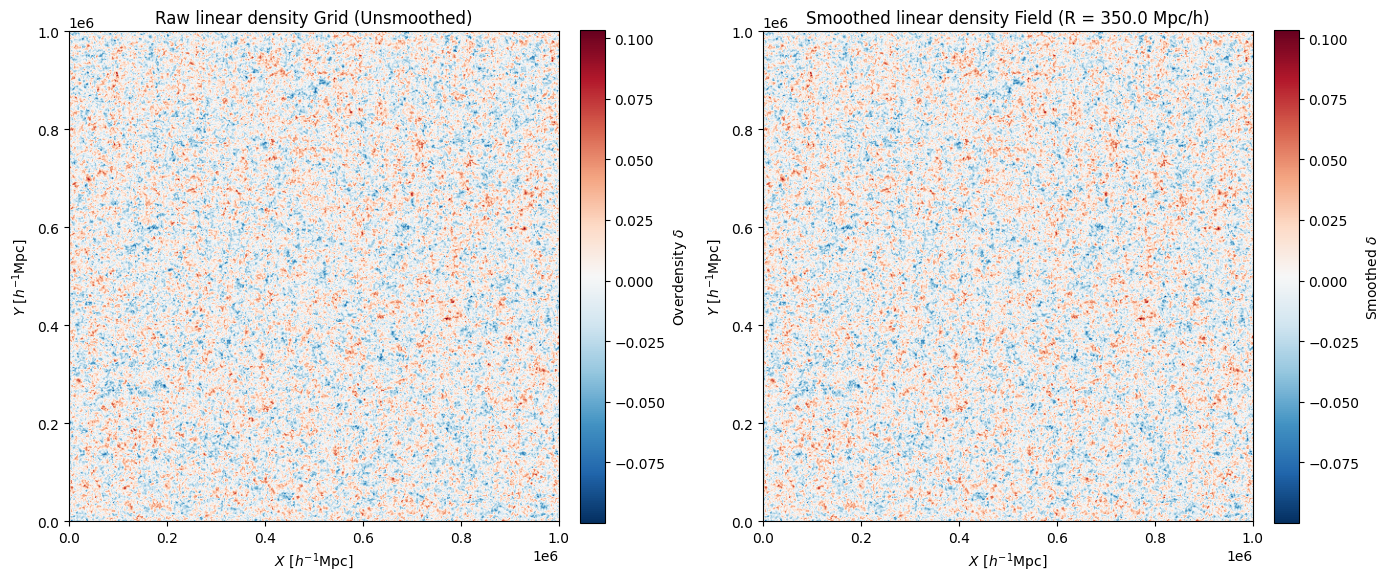

In [25]:
#density field 2d slice

#middle slice along the Z-axis
mid_idx = delta_L_smoothed.shape[0] // 2

slice_raw = delta_L[:, :, mid_idx]      # Your raw unsmoothed grid
slice_smooth = delta_L_smoothed[:, :, mid_idx]  # Your smoothed array

#subplot 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# non smoothed
im0 = axes[0].imshow(
    slice_raw,
    cmap="RdBu_r",
    origin="lower",
    extent=[0, box_size, 0, box_size]  # Maps pixels to 50 Mpc/h physical box size
)
axes[0].set_title("Raw linear density Grid (Unsmoothed)")
axes[0].set_xlabel(r"$X\ [h^{-1}\text{Mpc}]$")
axes[0].set_ylabel(r"$Y\ [h^{-1}\text{Mpc}]$")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label=r"Overdensity $\delta$")

# Smoothed
im1 = axes[1].imshow(
    slice_smooth,
    cmap="RdBu_r",
    origin="lower",
    extent=[0, box_size, 0, box_size]
)
axes[1].set_title(f"Smoothed linear density Field (R = {R} Mpc/h)")
axes[1].set_xlabel(r"$X\ [h^{-1}\text{Mpc}]$")
axes[1].set_ylabel(r"$Y\ [h^{-1}\text{Mpc}]$")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label=r"Smoothed $\delta$")

plt.tight_layout()
plt.show()

In [6]:
#halo look up with read_IDs=True
redshift = 0.5
snapdir = "./"
snapnum = 3

FoF = readfof.FoF_catalog(
    snapdir, snapnum, long_ids=False, swap=False, SFR=False, read_IDs=True)

halo_sizes = FoF.GroupLen

#(readfof stores particle IDs in FoF.IDs or FoF.GroupIDs)
fof_particle_ids = FoF.IDs if hasattr(FoF, "IDs") else FoF.GroupIDs

halo_dict = {}
offset = 0

for i, length in enumerate(halo_sizes):
    current_halo_ids = fof_particle_ids[offset : offset + length]
    halo_dict[f"halo_{i}"] = current_halo_ids
    offset += length

np.savez_compressed("halo_id_lookup.npz", **halo_dict)
print("Saved particle IDs successfully!")


Saved particle IDs successfully!


In [9]:
print(all_init_IDs[:5])

[1 2 3 4 5]


In [7]:
#halo extent etc.
halo_centers = FoF.GroupPos
halo_1= np.load("halo_id_lookup.npz")["halo_1"]

print(len(halo_1))

halo_final_positions = final_positions_sorted[halo_1-1] #particle IDs start from 1 not 0, npy indexing starts from 0

d_halo_1 = halo_final_positions - halo_centers[1]                 # (Np , 3) displacements
d_halo_1 -= box_size * np.round(d_halo_1 / box_size)                       # minimum image

extent = d_halo_1.max(axis=0) - d_halo_1.min(axis=0)         # per-axis extent (x, y, z)
#center_x = np.median(halo_final_positions[:,0]) #these are eulerian positions, need to trace the positions back
#center_y = np.median(halo_final_positions[:,1]) 
#center_z = np.median(halo_final_positions[:,2]) 

halo_center_final = halo_centers[1]
print("halo_1 center from FoF: ", halo_centers[1])
print("extent = ",extent)

2801
halo_1 center from FoF:  [809902.8  918570.94 983940.44]
extent =  [272573.38 117138.5  481345.7 ]


In [49]:
#halo variance

#z=127
density_halo = in_sphere(all_init_positions, delta_L_sm_p,halo_center_final,3.7e3,box_size)

mean_halo = np.mean(density_halo)
var_halo = np.var(density_halo)

print("variance centered at halo, z=127: ",var_halo)

#z=0.5
density_halo_fin = in_sphere(final_positions_sorted, delta_L_sm_p,halo_center_final,3.7e3,box_size)

mean_halo_fin = np.mean(density_halo_fin)
var_halo_fin = np.var(density_halo_fin)

print("variance centered at halo, z=0.5: ",var_halo_fin)

variance centered at halo, z=127:  0.00022489797
variance centered at halo, z=0.5:  0.0005064481


In [70]:
#halo variances table (NOT WORKING/TOO SLOW)
# Assuming halo_centers is an array or list containing the 3D coordinates of your halos
# e.g., halo_centers = FoF.GroupPos[:10]

results = []

for i in range(10):
    center = halo_centers[i]  # Get final position for halo i

    # z = 127 calculation (Initial positions around halo center)
    density_init = in_sphere(
        all_init_positions, delta_L_sm_p, center, 3.7e3, box_size
    )
    mean_init = np.mean(density_init)
    var_init = np.var(density_init)

    # z = 0.5 calculation (Final positions around halo center)
    density_fin = in_sphere(
        final_positions_sorted, delta_L_sm_p, center, 3.7e3, box_size
    )
    mean_fin = np.mean(density_fin)
    var_fin = np.var(density_fin)

    results.append(
        {
            "Halo Index": i,
            "Mean (z=127)": mean_init,
            "Var (z=127)": var_init,
            "Mean (z=0.5)": mean_fin,
            "Var (z=0.5)": var_fin,
        }
    )

# Create DataFrame and print as Markdown
df = pd.DataFrame(results)
print(df.to_markdown(index=False))

|   Halo Index |   Mean (z=127) |   Var (z=127) |   Mean (z=0.5) |   Var (z=0.5) |
|-------------:|---------------:|--------------:|---------------:|--------------:|
|            0 |      0.0368569 |   0.000208584 |     0.00844033 |   0.000505808 |
|            1 |      0.0264732 |   0.000242912 |     0.00828981 |   0.00052822  |
|            2 |      0.0373065 |   0.0004548   |     0.00688292 |   0.000491445 |
|            3 |      0.0353531 |   9.59208e-05 |     0.00694311 |   0.000510205 |
|            4 |      0.0173805 |   0.000425115 |     0.00651404 |   0.00050905  |
|            5 |      0.0342805 |   0.000193388 |     0.007514   |   0.000562795 |
|            6 |      0.0628209 |   0.000630883 |     0.00642277 |   0.000548519 |
|            7 |      0.0318737 |   0.000270147 |     0.00512877 |   0.000457801 |
|            8 |      0.0297812 |   0.000372291 |     0.0037676  |   0.000550749 |
|            9 |      0.0386005 |   0.000510388 |     0.00734879 |   0.000486892 |


In [ ]:
#over/underdense positions
perc_low = np.percentile(delta_L_sm_p,0.00001)
perc_high = np.percentile(delta_L_sm_p,99.99999) 
min_delta = np.min(delta_L_smoothed)
print(min_delta)
print(perc_low)

low_delta_idx = [idx for idx,delta in enumerate(delta_L_sm_p) if delta <= perc_low]
high_delta_idx = [idx for idx,delta in enumerate(delta_L_sm_p) if delta >= perc_high]


print("positions with density in the 0.00001st percentile:")
pos_low_perc = all_init_positions[low_delta_idx]

print("positions with density in the 99.99999th percentile:")
pos_high_perc = all_init_positions[high_delta_idx]

print("stored")

-0.128155
-0.10907405896370485
positions with density in the 0.00001st percentile:
positions with density in the 99.99999th percentile:
stored


In [ ]:
#overdense centered vs. underdense centered variance 

#z=127
density_overdense = in_sphere(all_init_positions,delta_L_sm_p, pos_high_perc[1],3.7e3,box_size)
mean_od = np.mean(density_overdense)
var_od = np.var(density_overdense)
print("pos:", pos_high_perc[1])
print(var_od)

density_underdense = in_sphere(all_init_positions,delta_L_sm_p, pos_low_perc[1],3.7e3,box_size)
mean_ud = np.mean(density_underdense)
var_ud = np.var(density_underdense)
print("pos:", pos_low_perc[1])
print(var_ud)

#z=0.5
density_overdense_fin = in_sphere(final_positions_sorted,delta_L_sm_p, pos_high_perc[1],3.7e3,box_size)
mean_od_fin = np.mean(density_overdense_fin)
var_od_fin = np.var(density_overdense_fin)
print("pos:", pos_high_perc[1])
print("fin od var: ", var_od_fin)

density_underdense_fin = in_sphere(final_positions_sorted,delta_L_sm_p, pos_low_perc[1],3.7e3,box_size)
mean_ud_fin = np.mean(density_underdense_fin)
var_ud_fin = np.var(density_underdense_fin)
print("pos:", pos_low_perc[1])
print("fin ud var: ",var_ud_fin)

pos: [292989.12 329986.8  763649.25]
0.00075701834
pos: [ 80115.46 349638.72 933564.4 ]
0.0007529109
pos: [292989.12 329986.8  763649.25]
fin od var:  0.0005156693
pos: [ 80115.46 349638.72 933564.4 ]
fin ud var:  4.0055593e-06


In [ ]:
#VARIANCE TABLE BY RADII

def sphere_stats(pos, vals, centre, radii, L):
    """Count, mean and variance of `vals` for particles within each radius of `centre`.
    pos: (Np,3) positions, vals: (Np,) per-particle values, L: box size (same units)."""
    radii = np.asarray(radii, dtype=np.float64)
    R_max = radii.max()
    if R_max >= L / 2:
        raise ValueError("largest radius must be < L/2")

    # cheap prefilter on x (small margin guards against float32 round-off)
    cx = np.asarray(centre, dtype=pos.dtype)
    dx = pos[:, 0] - cx[0]
    dx -= pos.dtype.type(L) * np.rint(dx / pos.dtype.type(L))
    cand = np.flatnonzero(np.abs(dx) < 1.001 * R_max)

    # exact periodic distances for the survivors only, in float64
    d = pos[cand].astype(np.float64) - np.asarray(centre, dtype=np.float64)
    d -= L * np.rint(d / L)
    r = np.sqrt((d**2).sum(axis=1))

    keep = r < R_max
    r, v = r[keep], vals[cand[keep]].astype(np.float64)

    order = np.argsort(r)                       # sort by distance once
    r, v = r[order], v[order]
    v0 = v.mean() if len(v) else 0.0            # shift for numerical stability
    w = v - v0
    c1, c2 = np.cumsum(w), np.cumsum(w * w)

    n = np.searchsorted(r, radii, side="left")  # particles with r < R, for each R
    with np.errstate(invalid="ignore", divide="ignore"):
        m1 = np.where(n > 0, c1[np.maximum(n - 1, 0)] / n, np.nan)
        m2 = np.where(n > 0, c2[np.maximum(n - 1, 0)] / n, np.nan)
    return pd.DataFrame({"R": radii, "N": n, "mean": v0 + m1, "var": m2 - m1**2})

radii = np.array([0.5e3, 1e3, 2e3, 3.7e3, 5e3])   # <- your radii of interest, in kpc/h
halo = 1                                            # <- which halo

centre_final = halo_centers[halo]                   # FoF centre at z=0.5

# Centre for the z=127 positions. Option A: Lagrangian centre of the halo's own particles
# (assumes halo_1 indexes all_init_positions the same way as final_positions_sorted)
p0 = all_init_positions[halo_1]
d = p0 - p0[0]
d -= box_size * np.round(d / box_size)
centre_init = (p0[0] + np.median(d, axis=0)) % box_size
# Option B: use the same centre as the final one, as in your earlier loop
# centre_init = centre_final

for label, pos, c in [("z=127", all_init_positions, centre_init),
                      ("z=0.5", final_positions_sorted, centre_final)]:
    print(f"\nHalo {halo}, {label}, centre = {c}")
    print(sphere_stats(pos, delta_L_sm_p, c, radii, box_size).to_markdown(index=False))


Halo 1, z=127, centre = [873046.7  435552.53 371078.75]
|    R |   N |        mean |         var |
|-----:|----:|------------:|------------:|
|  500 |   1 | -0.00596759 | 0           |
| 1000 |   1 | -0.00596759 | 0           |
| 2000 |   5 | -0.00826186 | 8.28139e-05 |
| 3700 |  27 |  0.00188692 | 0.000223349 |
| 5000 |  81 |  0.00876885 | 0.000442456 |

Halo 1, z=0.5, centre = [809902.8  918570.94 983940.44]
|    R |    N |       mean |         var |
|-----:|-----:|-----------:|------------:|
|  500 |  237 | 0.0063524  | 0.000502581 |
| 1000 |  901 | 0.00806184 | 0.000522456 |
| 2000 | 1988 | 0.00834919 | 0.000539208 |
| 3700 | 2946 | 0.00828981 | 0.00052822  |
| 5000 | 3381 | 0.00847137 | 0.000514339 |


In [ ]:
#variance table by CENTER
#QUESTION: why do the x-cut??

def in_sphere_pre(pos, vals, centre, R, L):
    L32 = np.float32(L)
    dx = pos[:, 0] - np.float32(centre[0])
    dx -= L32 * np.rint(dx / L32)
    cand = np.flatnonzero(np.abs(dx) < R)            # ~2R/L of the particles survive
    d = pos[cand] - np.asarray(centre, dtype=np.float32)
    d -= L32 * np.rint(d / L32)
    return vals[cand[(d**2).sum(axis=1) < np.float32(R * R)]]

#halo variances TABLE
# Assuming halo_centers is an array or list containing the 3D coordinates of your halos
# e.g., halo_centers = FoF.GroupPos[:10]

results = []

for i in range(10):
    center = halo_centers[i]  # Get final position for halo i

    # z = 127 calculation (Initial positions around halo center)
    density_init = in_sphere_pre(
        all_init_positions, delta_L_sm_p, center, 3.7e3, box_size
    )
    mean_init = np.mean(density_init)
    var_init = np.var(density_init)

    # z = 0.5 calculation (Final positions around halo center)
    density_fin = in_sphere_pre(
        final_positions_sorted, delta_L_sm_p, center, 3.7e3, box_size
    )
    mean_fin = np.mean(density_fin)
    var_fin = np.var(density_fin)

    results.append(
        {
            "Halo Index": i,
            "Mean (z=127)": mean_init,
            "Var (z=127)": var_init,
            "Mean (z=0.5)": mean_fin,
            "Var (z=0.5)": var_fin,
        }
    )

# Create DataFrame and print as Markdown
df = pd.DataFrame(results)
print(df.to_markdown(index=False))

|   Halo Index |   Mean (z=127) |   Var (z=127) |   Mean (z=0.5) |   Var (z=0.5) |
|-------------:|---------------:|--------------:|---------------:|--------------:|
|            0 |      0.0368569 |   0.000208584 |     0.00844033 |   0.000505808 |
|            1 |      0.0264732 |   0.000242912 |     0.00828981 |   0.00052822  |
|            2 |      0.0373065 |   0.0004548   |     0.00688292 |   0.000491445 |
|            3 |      0.0353531 |   9.59208e-05 |     0.00694311 |   0.000510205 |
|            4 |      0.0173805 |   0.000425115 |     0.00651404 |   0.00050905  |
|            5 |      0.0342805 |   0.000193388 |     0.007514   |   0.000562795 |
|            6 |      0.0628209 |   0.000630883 |     0.00642277 |   0.000548519 |
|            7 |      0.0318737 |   0.000270147 |     0.00512877 |   0.000457801 |
|            8 |      0.0297812 |   0.000372291 |     0.0037676  |   0.000550749 |
|            9 |      0.0386005 |   0.000510388 |     0.00734879 |   0.000486892 |


In [11]:
#radii sorted by distance
import numpy as np

def _sorted_sphere(pos, vals, centre, R_max, L):
    """Returns (idx, r, v) for particles with r < R_max around centre, sorted by distance.
    idx indexes the ORIGINAL arrays pos / vals."""
    if R_max >= L / 2:
        raise ValueError("radius must be < L/2")
    dt = pos.dtype
    cx = np.asarray(centre, dtype=dt)
    dx = pos[:, 0] - cx[0]
    dx -= dt.type(L) * np.rint(dx / dt.type(L))
    cand = np.flatnonzero(np.abs(dx) < 1.001 * R_max)
    d = pos[cand].astype(np.float64) - np.asarray(centre, dtype=np.float64)
    d -= L * np.rint(d / L)
    r = np.sqrt((d**2).sum(axis=1))
    keep = r < R_max
    idx = cand[keep]                                  # <- new: remember who each particle is
    r, v = r[keep], vals[idx].astype(np.float64)
    order = np.argsort(r)
    return idx[order], r[order], v[order]


In [12]:
#BIAS AS A FUNCTION OF COLLECTING SPHERE RADIUS
def bias_vs_radius_pointwise(pos, vals, centre, radii, L, var_norm=None):
    radii = np.asarray(radii, dtype=np.float64)
    idx, r, v = _sorted_sphere(pos, vals, centre, radii.max(), L)
    n = np.searchsorted(r, radii, side="left")
    w = v - (v.mean() if len(v) else 0.0)
    c1, c2 = np.cumsum(w), np.cumsum(w * w)
    var = np.full(len(radii), np.nan)
    bias = np.full((len(v), len(radii)), np.nan)
    for k, nk in enumerate(n):
        if nk > 0:
            var[k] = c2[nk - 1] / nk - (c1[nk - 1] / nk) ** 2
            norm = var[k] if var_norm is None else var_norm
            if norm > 0:
                bias[:nk, k] = v[:nk] / norm
    return dict(idx=idx, r=r, delta=v, bias=bias, var=var, n=n, radii=radii)



#radii = np.array([2e3, 3.7e3, 5e3, 1e4, 3.7e4, 7e4])       # kpc/h, all below box_size/2
#centre_final = halo_centers[1]                              # FoF centre of your halo
#var_global = np.var(delta_L_p, dtype=np.float64)

#res = bias_vs_radius_pointwise(final_positions_sorted, delta_L_p, centre_final, radii, box_size,
#                               var_norm=var_global)
#bias_rad_fin, var_rad, n_rad = res["bias"], res["var"], res["n"]

#print("particles per radius:", n_rad)
#print("mean bias per radius:", np.nanmean(bias_rad_fin, axis=0))
#print(res["bias"][:10])


In [14]:
#faster variance computation
def var_vs_radius(pos, vals, centre, radii, L):
    radii = np.asarray(radii, dtype=np.float64)
    idx, r, v = _sorted_sphere(pos, vals, centre, radii.max(), L)

    n = np.searchsorted(r, radii, side="left")      # particles inside each radius

    w = v - (v.mean() if len(v) else 0.0)           # shift for numerical stability
    c1 = np.concatenate(([0.0], np.cumsum(w, dtype=np.float64)))
    c2 = np.concatenate(([0.0], np.cumsum(w * w, dtype=np.float64)))

    n_safe = np.maximum(n, 1)
    var = c2[n] / n_safe - (c1[n] / n_safe) ** 2
    var[n == 0] = np.nan

    return dict(r=r, var=var, n=n, radii=radii)

In [8]:
#replacement for _sorted_sphere and the bias/var_vs_radius functions, now it bins. should be faster 

def var_vs_radius_binned(pos, vals, centre, radii, L):
    radii = np.asarray(radii, dtype=np.float64)
    R_max = radii.max()
    if R_max >= L / 2:
        raise ValueError("radius must be < L/2")

    # same selection as your _sorted_sphere, minus the sort
    dx = pos[:, 0] - centre[0]
    dx -= L * np.rint(dx / L)
    cand = np.flatnonzero(np.abs(dx) < 1.001 * R_max)
    d = pos[cand].astype(np.float64) - np.asarray(centre, dtype=np.float64)
    d -= L * np.rint(d / L)
    r = np.sqrt((d * d).sum(axis=1))
    keep = r < R_max
    r = r[keep]
    v = vals[cand[keep]].astype(np.float64)

    # binning: which shell does each particle fall in?
    shell = np.searchsorted(radii, r, side="left")   # 0 .. len(radii)-1
    K = len(radii)

    w = v - v.mean()
    n_shell  = np.bincount(shell, minlength=K)
    s1_shell = np.bincount(shell, weights=w,     minlength=K)
    s2_shell = np.bincount(shell, weights=w * w, minlength=K)

    # running totals = everything inside each radius
    n  = np.cumsum(n_shell)
    c1 = np.cumsum(s1_shell)
    c2 = np.cumsum(s2_shell)

    n_safe = np.maximum(n, 1)
    var = c2 / n_safe - (c1 / n_safe) ** 2
    var[n == 0] = np.nan
    return dict(var=var, n=n, radii=radii)

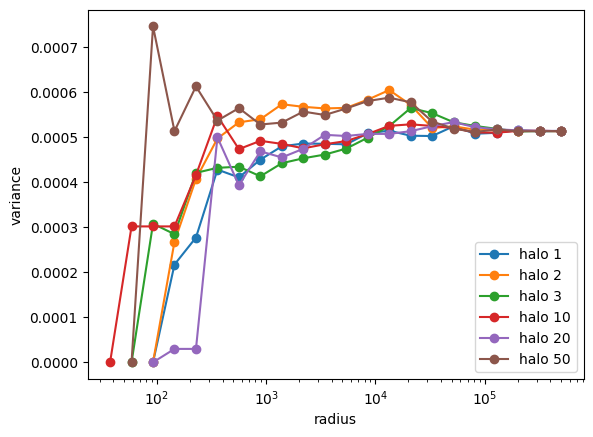

In [ ]:
#attempt to plot - halos
radii = np.logspace(0, np.log10(0.5e6), 30)   # see note below
var_global = np.var(delta_L_p, dtype=np.float64)

for i in (1, 2, 3, 10, 20, 50):
    res = var_vs_radius_binned(final_positions_sorted, delta_L_p, halo_centers[i], radii, box_size)
    plt.plot(radii, res["var"], "o-", label=f"halo {i}")
    plt.xscale("log")
    del res                      # free memory before the next halo

plt.xlabel("radius")
plt.ylabel("variance")
plt.legend()
plt.show()

In [ ]:
#BIAS AS A FUNCTION OF CENTER POSITION
def bias_vs_centre(pos, vals, centres, R, L):
    """Several centres, one radius.
    bias_cen has shape (len(centres), max_N). Row j holds delta_i / var_j for the particles within R
    of centres[j], where var_j is the variance of delta over that sphere (rows padded with NaN)."""
    vs = [_sorted_sphere(pos, vals, c, R, L)[1] for c in centres]
    n = np.array([len(v) for v in vs])
    var = np.array([v.var() if len(v) else np.nan for v in vs])
    bias_cen = np.full((len(centres), n.max()), np.nan)
    for j, v in enumerate(vs):
        if n[j] > 0 and var[j] > 0:
            bias_cen[j, :n[j]] = v / var[j]**2
    return bias_cen, var, n

# 2. many centres, one radius
centres = halo_centers[:10]                              # <- any (M, 3) array of centres
bias_cen, var_cen, n_cen = bias_vs_centre(all_init_positions, delta_L_p,
                                          centres, 3.7e3, box_size)

print("mean bias per centre:", np.nanmean(bias_cen, axis=1))

mean bias per centre: [ 847141.81271477  448650.51676858  180361.21819192 3842378.29082481
   96171.98122745  916617.43665217  157835.68260615  436747.89081139
  214869.77418158  148180.31208597]


In [ ]:
#VOID CENTERS

# Pylians works in Mpc/h; your Gadget positions are in kpc/h
BoxSize = box_size / 1e3
dims    = 512                                              # grid cells per side
pos     = (final_positions_sorted / 1e3).astype(np.float32)   # all_final_positions works too: order doesn't matter here

# 1. density contrast delta = rho/mean - 1 on the grid
delta = np.zeros((dims, dims, dims), dtype=np.float32)
MASL.MA(pos, delta, BoxSize, 'CIC')
delta /= np.mean(delta, dtype=np.float64)
delta -= 1.0

# 2. void finder parameters
threshold = -0.8                          # mean delta inside each void (-0.7 / -0.8 are typical)
cell  = BoxSize / dims                    # grid cell size (Mpc/h)
Rmin  = 5 * cell                          # smallest void radius to search (>= ~4-5 cells)
Rmax  = 50.0                              # largest void radius (Mpc/h), adjust to your box
bins  = 30
Radii = np.logspace(np.log10(Rmin), np.log10(Rmax), bins + 1, dtype=np.float32)
threads1 = threads2 = 8                   # OpenMP threads

V = VL.void_finder(delta, BoxSize, threshold, Radii,
                   threads1, threads2, void_field=False)

void_centres = V.void_pos * 1e3           # (Nvoids, 3), back to kpc/h like your other arrays
void_radii   = V.void_radius * 1e3        # kpc/h
print(len(void_centres), "voids")

maximum number of voids = 256336

Smoothing field with top-hat filter of radius 50.00
Density smoothing took 2.934 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 47.35
Density smoothing took 2.493 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 44.84
Density smoothing took 2.523 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 42.47
Density smoothing took 2.680 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 40.22
Density smoothing took 1.939 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 38.09
Density smoothing took 1.955 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 36.07
Density smoothing took 1.830 seconds
No cells with delta < -0.80

Smoothing field with top-hat filter of radius 34.16
Density smoothing took 2.420 seconds
No cells with delta < -0.80

Smoothing field with t

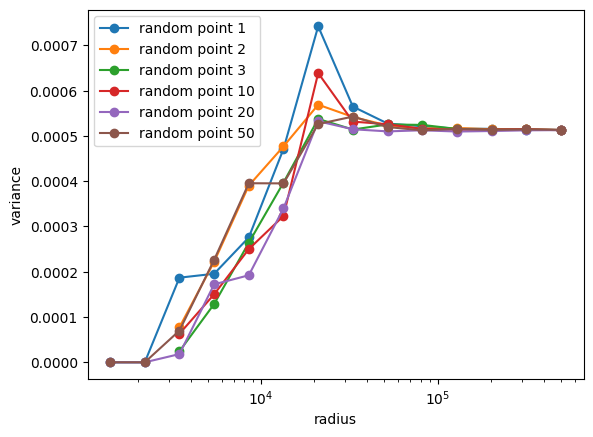

In [11]:
#attempt to plot - voids
radii = np.logspace(0, np.log10(0.5e6), 30)   # see note below
var_global = np.var(delta_L_p, dtype=np.float64)

for i in (1, 2, 3, 10, 20, 50):
    res = var_vs_radius_binned(final_positions_sorted, delta_L_p, void_centres[i], radii, box_size)
    plt.plot(radii, res["var"], "o-", label=f"random point {i}")
    plt.xscale("log")
    del res                      # free memory before the next halo

plt.xlabel("radius")
plt.ylabel("variance")
plt.legend()
plt.show()

In [12]:
#BIAS PER VOID CENTER
def bias_vs_centre(pos, vals, centres, R, L):
    """Several centres, one radius.
    bias_cen has shape (len(centres), max_N). Row j holds delta_i / var_j for the particles within R
    of centres[j], where var_j is the variance of delta over that sphere (rows padded with NaN)."""
    vs = [_sorted_sphere(pos, vals, c, R, L)[1] for c in centres]
    n = np.array([len(v) for v in vs])
    var = np.array([v.var() if len(v) else np.nan for v in vs])
    bias_cen = np.full((len(centres), n.max()), np.nan)
    for j, v in enumerate(vs):
        if n[j] > 0 and var[j] > 0:
            bias_cen[j, :n[j]] = v / var[j]**2
    return bias_cen, var, n

# 2. many centres, one radius
centres = void_centres[:10]                              # <- any (M, 3) array of centres
bias_cen, var_cen, n_cen = bias_vs_centre(all_init_positions, delta_L_p,
                                          centres, 3.7e3, box_size)

print("mean bias per void centre:", np.nanmean(bias_cen, axis=1))
print("variance per void centre:")

mean bias per void centre: [1.03035808e-08 1.00654642e-08 1.04231011e-08 1.03590169e-08
 1.01082980e-08 1.03170467e-08 1.03568533e-08 1.01765514e-08
 1.00312887e-08 1.02954468e-08]
variance per void centre:


In [13]:
#TABLE
radii = np.array([2e3, 3.7e3, 5e3, 1e4, 3.7e4, 7e4])       # kpc/h, all below box_size/2
centre_halo_0 = halo_centers[0]                              # FoF centre of your halo
centre_void_0 = void_centres[0]
var_global = np.var(delta_L_p, dtype=np.float64)

def radius_table(results, radii, n_part=3):
    """Rows = radii. For each centre: variance, then the bias of the n_part particles nearest the centre."""
    cols = {}
    for label, res in results.items():
        cols[(label, "variance")] = res["var"]
        for j in range(n_part):
            cols[(label, f"bias p{j+1}")] = (res["bias"][j, :] if j < res["bias"].shape[0]
                                              else np.full(len(radii), np.nan))
    df = pd.DataFrame(cols, index=pd.Index(radii, name="R [kpc/h]"))
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df

def print_table(df, fmt=lambda x: f"{x:.4g}", in_sep=" | ", group_sep="     |     "):
    """Plain-text table with vertical bars between columns and a wider gap between centres."""
    labels = [c[0] for c in df.columns]
    names  = [c[1] for c in df.columns]
    cells  = [[fmt(v) if pd.notna(v) else "NaN" for v in df[c]] for c in df.columns]
    idx    = [f"{v:.1f}" for v in df.index]
    w      = [max(len(n), *(len(s) for s in col)) for n, col in zip(names, cells)]
    w_idx  = max(len(df.index.name), *(len(s) for s in idx))

    def sep(i):                                   # separator placed before column i
        return group_sep if labels[i] != labels[i - 1] else in_sep

    def row(first, vals):
        out = first.ljust(w_idx)
        for i, v in enumerate(vals):
            out += (in_sep if i == 0 else sep(i)) + v.rjust(w[i])
        return out

    line1, i = " " * w_idx, 0                     # centre each group label over its columns
    while i < len(labels):
        j = i
        while j < len(labels) and labels[j] == labels[i]:
            j += 1
        span = sum(w[i:j]) + len(in_sep) * (j - i - 1)
        line1 += (in_sep if i == 0 else group_sep) + labels[i].center(span)
        i = j

    print(line1)
    print(row("", names))
    print(row(df.index.name, [""] * len(names)))
    for r in range(len(df)):
        print(row(idx[r], [cells[c][r] for c in range(len(names))]))

def extra_info(results):
    """Everything that isn't in the table, printed underneath it."""
    for label, res in results.items():
        nk = res["n"]
        md = [res["delta"][:n].mean() if n else np.nan for n in nk]
        mb = [np.nanmean(res["bias"][:n, k]) if n else np.nan for k, n in enumerate(nk)]
        print(f"  {label}: N per radius = {nk}")
        print(f"  {label}: mean density = {np.round(md, 5)}")
        print(f"  {label}: mean bias    = {np.round(mb, 3)}")

# z, positions at that redshift, and the centres to compare
setups = [(127, all_init_positions,     {"halo_0": centre_halo_0, "void_0": centre_void_0}),
          (0.5, final_positions_sorted, {"halo_0": centre_halo_0, "void_0": centre_void_0})]

for z, pos, centres in setups:
    results = {label: bias_vs_radius_pointwise(pos, delta_L_p, c, radii, box_size, var_norm=var_global) #should I be putting global variance here??? it's blowing up otherwise
               for label, c in centres.items()}
    print(f"\n=== z = {z} ===")
    print_table(radius_table(results, radii))
    extra_info(results)

print("USED GLOBAL VARIANCE IN THE BIAS FORMULA")

#NOTES:
#p1, p2 and p3 are the closest, second closest and 3rd closest particles to the center valye passed to the functio, these are the bias values extracted


=== z = 127 ===
          |                  halo_0                     |                      void_0                
          |  variance | bias p1 | bias p2 | bias p3     |      variance | bias p1 | bias p2 | bias p3
R [kpc/h] |           |         |         |             |               |         |         |        
2000.0    | 4.294e-05 |   29.07 |   56.91 |   51.31     |     0.0001538 |  -71.99 |  -106.7 |    -114
3700.0    |  0.000229 |   29.07 |   56.91 |   51.31     |     0.0004654 |  -71.99 |  -106.7 |    -114
5000.0    | 0.0002661 |   29.07 |   56.91 |   51.31     |     0.0004958 |  -71.99 |  -106.7 |    -114
10000.0   | 0.0004177 |   29.07 |   56.91 |   51.31     |     0.0006533 |  -71.99 |  -106.7 |    -114
37000.0   | 0.0005557 |   29.07 |   56.91 |   51.31     |     0.0005199 |  -71.99 |  -106.7 |    -114
70000.0   | 0.0005255 |   29.07 |   56.91 |   51.31     |     0.0005025 |  -71.99 |  -106.7 |    -114
  halo_0: N per radius = [     6     30     70    574  28713 1928

In [ ]:
#variance distrIbution CLAUDE
import numpy as np
import scipy.fft as sfft

def variance_field(pos, vals, L, R, ng=512, min_particles=30):
    """Variance of vals inside a sphere of radius R centred on every cell of an ng^3 grid."""
    cell = L / ng #size of one cell
    w = vals.astype(np.float64) - vals.mean() #delta - mean delta (why?)

    # deposit particles onto the grid (nearest-cell assignment)
    ix = np.floor(pos / L * ng).astype(np.int64) % ng
    flat = (ix[:, 0] * ng + ix[:, 1]) * ng + ix[:, 2]
    g_n  = np.bincount(flat, minlength=ng**3).reshape(ng, ng, ng).astype(np.float64)
    
    g_w  = np.bincount(flat, weights=w,     minlength=ng**3).reshape(ng, ng, ng)
    g_w2 = np.bincount(flat, weights=w * w, minlength=ng**3).reshape(ng, ng, ng)

    # spherical top-hat window in Fourier space
    kx = 2 * np.pi * sfft.fftfreq(ng, d=cell)
    kz = 2 * np.pi * sfft.rfftfreq(ng, d=cell)
    kk = np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)
    x = kk * R
    x[0, 0, 0] = 1.0
    W = 3 * (np.sin(x) - x * np.cos(x)) / x**3
    W[0, 0, 0] = 1.0
    del x, kk

    def smooth(g):
        return sfft.irfftn(sfft.rfftn(g, workers=-1) * W, s=(ng,) * 3, workers=-1)

    n  = smooth(g_n)       # mean count per cell inside the sphere
    c1 = smooth(g_w)
    c2 = smooth(g_w2)

    cells_in_sphere = 4 / 3 * np.pi * R**3 / cell**3
    good = n * cells_in_sphere >= min_particles      # enough particles to trust the variance
    n_safe = np.where(good, n, 1.0)
    var = c2 / n_safe - (c1 / n_safe) ** 2
    var[~good] = np.nan
    return var.astype(np.float32)

In [49]:
#CLAUDE
var_global = np.var(delta_L_p, dtype=np.float64)

radii_map = [1e2, 3e3, 2e4, 1e5, 3e5]          # a few radii; each costs 3 forward + 3 inverse FFTs
fields = {R: variance_field(all_init_positions, delta_L_p, box_size, R, ng=256)
          for R in radii_map}

Text(0, 0.5, 'PDF')

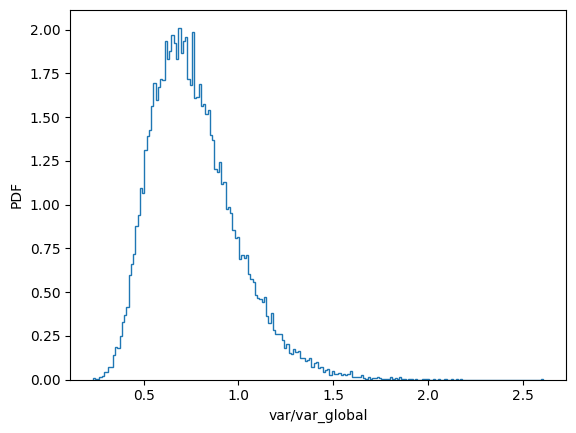

In [50]:

import matplotlib.pyplot as plt

R = radii_map[1]
f = fields[R]/var_global



# 2. the distribution of local variance across the box
plt.figure()
plt.hist(f[np.isfinite(f)].ravel(), bins=200, histtype="step", density=True)
plt.xlabel("var/var_global"); plt.ylabel("PDF")


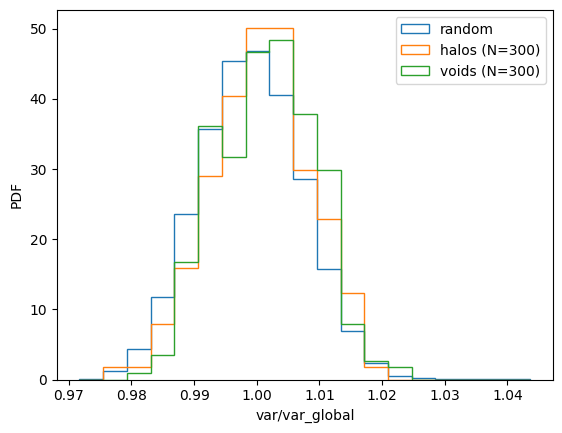

In [51]:
from scipy.ndimage import map_coordinates

rng = np.random.default_rng(0)
centers = rng.uniform(0, box_size, size=(100_000, 3))

def sample_field(field, centers, L):
    ng = field.shape[0]
    coords = (centers / L * ng - 0.5).T                   # grid values sit at cell centres
    return map_coordinates(field, coords, order=1, mode="grid-wrap")   # periodic box
R = 1e5
field = variance_field(final_positions_sorted, delta_L_p, box_size, R, ng=256)/var_global 

f_rand = sample_field(field, centers, box_size)
f_halo = sample_field(field, np.asarray(halo_centers[:300]) % box_size, box_size)
f_void = sample_field(field, np.asarray(void_centres[:300]) % box_size, box_size)
f_rand = f_rand[np.isfinite(f_rand)]
f_halo = f_halo[np.isfinite(f_halo)]
f_void = f_void[np.isfinite(f_void)]

# shared bin edges, covering both samples
lo = min(f_rand.min(), f_halo.min())
hi = max(f_rand.max(), f_halo.max())
bins = np.linspace(lo, hi, 20)

plt.hist(f_rand, bins=bins, histtype="step", density=True, label="random")
plt.hist(f_halo, bins=bins, histtype="step", density=True, label=f"halos (N={len(f_halo)})")
plt.hist(f_void, bins=bins, histtype="step", density=True, label=f"voids (N={len(f_void)})")
plt.xlabel("var/var_global"); plt.ylabel("PDF"); plt.legend()
plt.show()

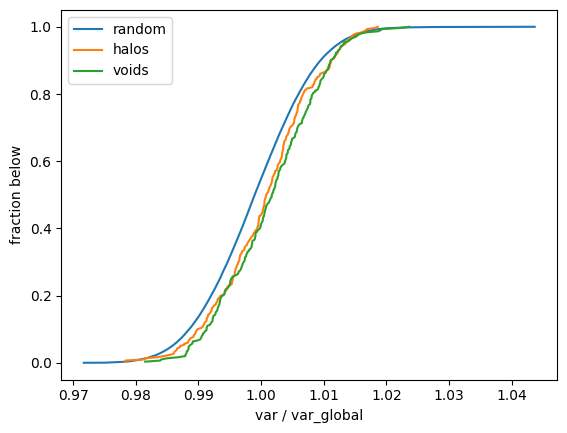

In [45]:
for f, name in [(f_rand, "random"), (f_halo, "halos"), (f_void, "voids")]:
    x = np.sort(f)
    plt.plot(x, np.arange(1, len(x) + 1) / len(x), label=name)
plt.xlabel("var / var_global"); plt.ylabel("fraction below"); plt.legend()

-1.5361934e-11


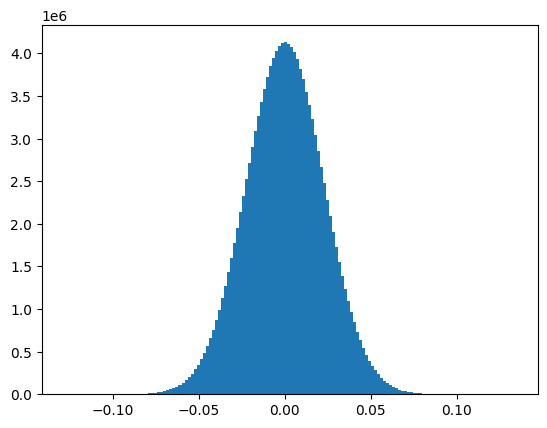

In [14]:
delta_L_p_flat = delta_L_p.flatten()

plt.hist(delta_L_p_flat, bins =150)

print(np.mean(delta_L_p))

In [16]:
#diagnostics2

print("IC IDs sorted:", np.all(np.diff(all_init_IDs) > 0), all_init_IDs[:5], all_init_IDs[-5:])

# are IDs lattice-ordered (ID-1 = ix*N^2 + iy*N + iz)?
N = 512; cell = box_size / N
i0 = all_init_IDs.astype(np.int64) - 1
lat = np.stack([i0 // N**2, (i0 // N) % N, i0 % N], axis=1) * cell
dd = all_init_positions - lat
dd -= box_size * np.round(dd / box_size)
print("max / rms offset from lattice (kpc/h):", np.abs(dd).max(), dd.std(), " cell =", cell)

# direct test of the pairing
init_order = np.argsort(all_init_IDs)
dL_sorted = delta_L_p[init_order]                 # index k <-> particle ID k+1
h0 = np.load("halo_id_lookup.npz")["halo_0"].astype(np.int64) - 1
print("mean dL over halo_0 members, current :", delta_L_p[h0].mean())
print("mean dL over halo_0 members, sorted  :", dL_sorted[h0].mean(), "(expect ~ +0.02)")

IC IDs sorted: True [1 2 3 4 5] [134217724 134217725 134217726 134217727 134217728]
max / rms offset from lattice (kpc/h): 500000.0 239352.82939589364  cell = 1953.125
mean dL over halo_0 members, current : 0.022204531
mean dL over halo_0 members, sorted  : 0.022204531 (expect ~ +0.02)
